1. Imports

In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as transforms
import torchvision.models as models
from IPython.display import HTML
from base64 import b64encode

2.Video Path & Info (with fallback FPS)

In [ ]:
VIDEO_PATH = "/content/v_Drumming_g25_c07.avi"

cap = cv2.VideoCapture(VIDEO_PATH)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
fps = cap.get(cv2.CAP_PROP_FPS)
width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
cap.release()

if fps <= 0 or fps != fps:
    fps = 25.0
    print("FPS metadata missing tha, fallback FPS = 25 set kiya")

print("Video Path:", VIDEO_PATH)
print("Total Frames in video:", total_frames)
print("FPS:", fps)
print("Original Resolution (Width x Height):", width, "x", height)
print("Duration (seconds):", round(total_frames / fps, 2))

Video Path: /content/v_Drumming_g25_c07.avi
Total Frames in video: 300
FPS: 25.0
Original Resolution (Width x Height): 320 x 240
Duration (seconds): 12.0


3. Function — Play Video Inline

In [ ]:
def play_video(video_path, width=400):
    mp4 = open(video_path, 'rb').read()
    data_url = "data:video/mp4;base64," + b64encode(mp4).decode()
    return HTML(f"""
    <video width="{width}" controls>
        <source src="{data_url}" type="video/mp4">
    </video>
    """)

4. Converting Original Video to MP4 (BEFORE Resizing)

In [ ]:
ORIGINAL_MP4_PATH_RAW = "/content/original_video_raw.mp4"

fourcc = cv2.VideoWriter_fourcc(*'mp4v')
out_orig = cv2.VideoWriter(ORIGINAL_MP4_PATH_RAW, fourcc, fps, (width, height))

cap2 = cv2.VideoCapture(VIDEO_PATH)
while True:
    ret, frame = cap2.read()
    if not ret:
        break
    out_orig.write(frame)
cap2.release()
out_orig.release()

ORIGINAL_MP4_PATH = "/content/original_video.mp4"
!ffmpeg -y -i "{ORIGINAL_MP4_PATH_RAW}" -c:v libx264 -pix_fmt yuv420p "{ORIGINAL_MP4_PATH}"

print("BEFORE RESIZING — Playing Original Video")
play_video(ORIGINAL_MP4_PATH)

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

5. Function — Extract Frames from Video

In [22]:
FRAMES_PER_VIDEO = 16

def extract_frames(video_path, num_frames=FRAMES_PER_VIDEO):
    cap = cv2.VideoCapture(video_path)
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    frame_indices = np.linspace(0, total - 1, num_frames, dtype=int)

    frames = []
    for idx in frame_indices:
        cap.set(cv2.CAP_PROP_POS_FRAMES, idx)
        ret, frame = cap.read()
        if ret:
            frame = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            frames.append(frame)
    cap.release()
    return frames

6. Extract Frames & Print BEFORE Info

In [ ]:
raw_frames = extract_frames(VIDEO_PATH)

print("Number of frames extracted:", len(raw_frames))
print("BEFORE Resize — shape of each frame:", raw_frames[0].shape)

Number of frames extracted: 16
BEFORE Resize — shape of each frame: (240, 320, 3)


7. Visualize Sample Frames — BEFORE Resizing

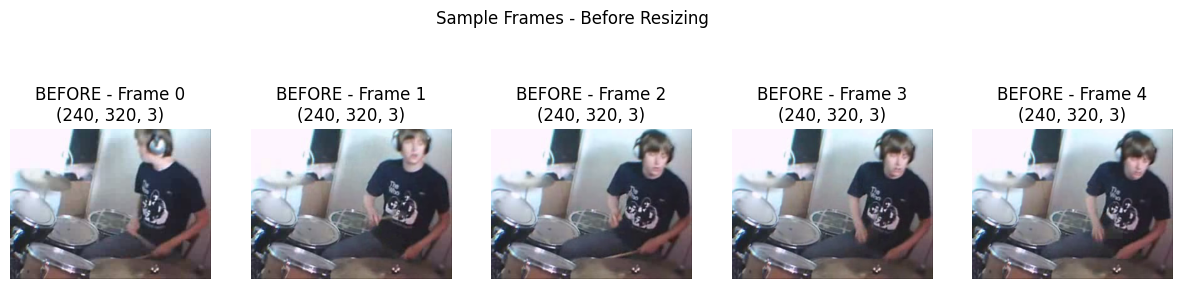

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i, ax in enumerate(axes):
    ax.imshow(raw_frames[i])
    ax.set_title(f"BEFORE - Frame {i}\n{raw_frames[i].shape}")
    ax.axis("off")
plt.suptitle("Sample Frames - Before Resizing")
plt.show()

8. Function — Resize Frames

In [ ]:
FRAME_SIZE = (224, 224)

def resize_frames(frames, size=FRAME_SIZE):
    return [cv2.resize(f, size, interpolation=cv2.INTER_AREA) for f in frames]

9. Resize & Print AFTER Info

In [ ]:
resized_frames = resize_frames(raw_frames)

print("AFTER Resize — shape of each frame:", resized_frames[0].shape)
print("Total frames (count unchanged):", len(resized_frames))

AFTER Resize — shape of each frame: (224, 224, 3)
Total frames (count unchanged): 16


10. Visualize Sample Frames — AFTER Resizing

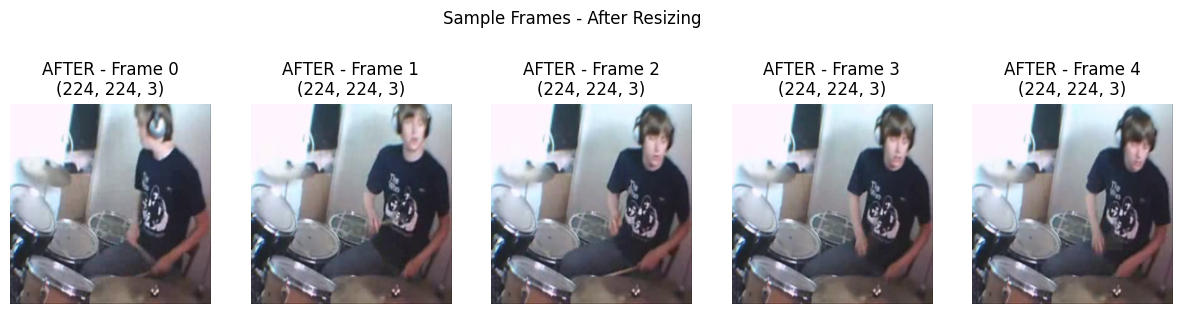

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))
for i, ax in enumerate(axes):
    ax.imshow(resized_frames[i])
    ax.set_title(f"AFTER - Frame {i}\n{resized_frames[i].shape}")
    ax.axis("off")
plt.suptitle("Sample Frames - After Resizing")
plt.show()

11. Video After Resizing and Play

In [ ]:
RESIZED_VIDEO_PATH_RAW = "/content/resized_video_raw.mp4"

out_resized = cv2.VideoWriter(RESIZED_VIDEO_PATH_RAW, fourcc, fps, FRAME_SIZE)
for frame in resized_frames:
    frame_bgr = cv2.cvtColor(frame, cv2.COLOR_RGB2BGR)
    out_resized.write(frame_bgr)
out_resized.release()

RESIZED_VIDEO_PATH = "/content/resized_video.mp4"
!ffmpeg -y -i "{RESIZED_VIDEO_PATH_RAW}" -c:v libx264 -pix_fmt yuv420p "{RESIZED_VIDEO_PATH}"

print("AFTER RESIZING — Playing Resized Video")
play_video(RESIZED_VIDEO_PATH)

ffmpeg version 6.1.1-3ubuntu5 Copyright (c) 2000-2023 the FFmpeg developers
  built with gcc 13 (Ubuntu 13.2.0-23ubuntu3)
  configuration: --prefix=/usr --extra-version=3ubuntu5 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --disable-omx --enable-gnutls --enable-libaom --enable-libass --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libglslang --enable-libgme --enable-libgsm --enable-libharfbuzz --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enable-libwebp --enable-libx265 --enable-libxml2 --enable-libxvid --enable-libzimg --ena

12. Video play Before and After Resizing

In [ ]:
from IPython.display import display

def play_video_side_by_side(video1_path, video2_path, label1="BEFORE", label2="AFTER", width=350):
    mp4_1 = open(video1_path, 'rb').read()
    data_url_1 = "data:video/mp4;base64," + b64encode(mp4_1).decode()

    mp4_2 = open(video2_path, 'rb').read()
    data_url_2 = "data:video/mp4;base64," + b64encode(mp4_2).decode()

    html_code = f"""
    <div style="display: flex; gap: 20px;">
        <div style="text-align: center;">
            <h4>{label1}</h4>
            <video width="{width}" controls>
                <source src="{data_url_1}" type="video/mp4">
            </video>
        </div>
        <div style="text-align: center;">
            <h4>{label2}</h4>
            <video width="{width}" controls>
                <source src="{data_url_2}" type="video/mp4">
            </video>
        </div>
    </div>
    """
    return HTML(html_code)

print("BEFORE vs AFTER — Side by Side Comparison")
display(play_video_side_by_side(ORIGINAL_MP4_PATH, RESIZED_VIDEO_PATH, "BEFORE Resizing", "AFTER Resizing"))

BEFORE vs AFTER — Side by Side Comparison


13. Before vs After — Summary

========== DIFFERENCE: BEFORE vs AFTER ==========
BEFORE - Resolution: 320 x 240
AFTER  - Resolution: 224 x 224
BEFORE - Frame size (pixels): 76800
AFTER  - Frame size (pixels): 50176
Size reduction ratio: 1.53x


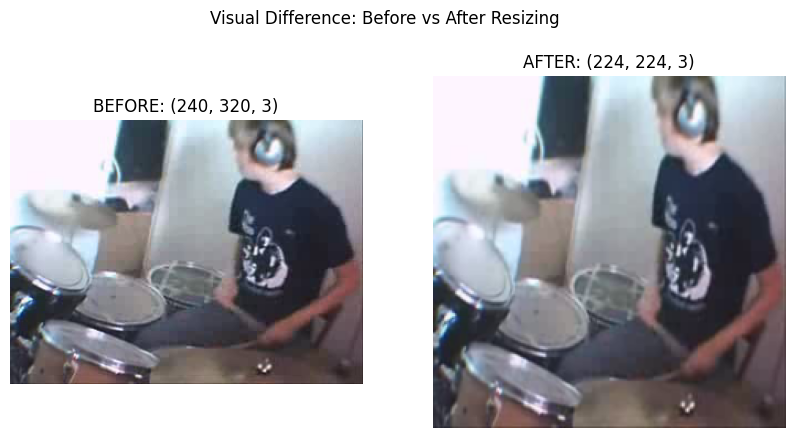

In [ ]:
print("========== DIFFERENCE: BEFORE vs AFTER ==========")
print(f"BEFORE - Resolution: {width} x {height}")
print(f"AFTER  - Resolution: {FRAME_SIZE[0]} x {FRAME_SIZE[1]}")
print(f"BEFORE - Frame size (pixels): {width*height}")
print(f"AFTER  - Frame size (pixels): {FRAME_SIZE[0]*FRAME_SIZE[1]}")
print(f"Size reduction ratio: {round((width*height)/(FRAME_SIZE[0]*FRAME_SIZE[1]), 2)}x")

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(raw_frames[0])
axes[0].set_title(f"BEFORE: {raw_frames[0].shape}")
axes[0].axis("off")

axes[1].imshow(resized_frames[0])
axes[1].set_title(f"AFTER: {resized_frames[0].shape}")
axes[1].axis("off")

plt.suptitle("Visual Difference: Before vs After Resizing")
plt.show()

14. Convert Frames into Array and Save

In [ ]:
frames_array = np.array(resized_frames)
print("Final processed frames array shape:", frames_array.shape)

OUTPUT_FRAMES_PATH = "/content/extracted_frames"
os.makedirs(OUTPUT_FRAMES_PATH, exist_ok=True)

save_name = os.path.splitext(os.path.basename(VIDEO_PATH))[0] + ".npy"
np.save(os.path.join(OUTPUT_FRAMES_PATH, save_name), frames_array)
print("Saved frames to:", os.path.join(OUTPUT_FRAMES_PATH, save_name))

Final processed frames array shape: (16, 224, 224, 3)
Saved frames to: /content/extracted_frames/v_Drumming_g25_c07.npy


15. Load Pretrained ResNet18 For Feature Extraction

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

resnet = models.resnet18(weights=models.ResNet18_Weights.DEFAULT)
resnet.fc = torch.nn.Identity()
resnet = resnet.to(device).eval()

preprocess = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                          std=[0.229, 0.224, 0.225])
])

print("ResNet18 loaded on:", device)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:01<00:00, 32.9MB/s]


ResNet18 loaded on: cpu


16. Extracting features From Frames

In [ ]:
def extract_cnn_features(frames_array):
    features = []
    with torch.no_grad():
        for frame in frames_array:
            tensor = preprocess(frame).unsqueeze(0).to(device)
            feat = resnet(tensor)
            features.append(feat.cpu().numpy().flatten())
    return np.array(features)

video_features = extract_cnn_features(frames_array)

print("BEFORE Feature Extraction — Frame shape:", frames_array[0].shape)
print("AFTER Feature Extraction — Feature vector shape (per frame):", video_features[0].shape)
print("Total feature matrix shape (all frames):", video_features.shape)

BEFORE Feature Extraction — Frame shape: (224, 224, 3)
AFTER Feature Extraction — Feature vector shape (per frame): (512,)
Total feature matrix shape (all frames): (16, 512)


17. Save all the Features

In [ ]:
FEATURES_OUTPUT_PATH = "/content/extracted_features"
os.makedirs(FEATURES_OUTPUT_PATH, exist_ok=True)

feat_save_name = os.path.splitext(os.path.basename(VIDEO_PATH))[0] + "_features.npy"
np.save(os.path.join(FEATURES_OUTPUT_PATH, feat_save_name), video_features)

print("Features saved to:", os.path.join(FEATURES_OUTPUT_PATH, feat_save_name))

Features saved to: /content/extracted_features/v_Drumming_g25_c07_features.npy


18. Summary

In [ ]:
print("========== SUMMARY ==========")
print(f"Video: {os.path.basename(VIDEO_PATH)}")
print(f"Total frames in original video: {total_frames}")
print(f"Frames extracted for processing: {len(raw_frames)}")
print(f"Frame shape BEFORE resize: {raw_frames[0].shape}")
print(f"Frame shape AFTER resize: {resized_frames[0].shape}")
print(f"Feature vector size per frame: {video_features.shape[1]}")
print(f"Final feature matrix shape: {video_features.shape}")
print("==============================")

========== SUMMARY ==========
Video: v_Drumming_g25_c07.avi
Total frames in original video: 300
Frames extracted for processing: 16
Frame shape BEFORE resize: (240, 320, 3)
Frame shape AFTER resize: (224, 224, 3)
Feature vector size per frame: 512
Final feature matrix shape: (16, 512)


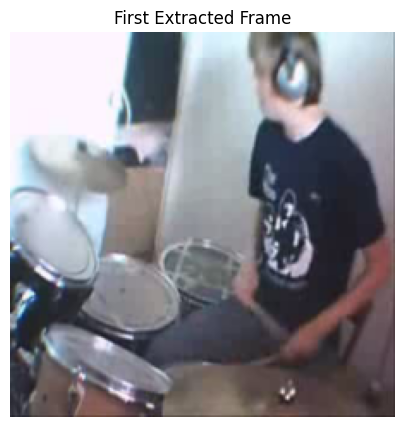

Total Frames Extracted: 16
Each Frame Shape: (224, 224, 3)


In [21]:

first_frame = resized_frames[0]

plt.figure(figsize=(5, 5))
plt.imshow(first_frame)
plt.title("First Extracted Frame")
plt.axis("off")
plt.show()

print(f"Total Frames Extracted: {len(resized_frames)}")
print(f"Each Frame Shape: {first_frame.shape}")

###Created By Areeba Khanam